<a href="https://colab.research.google.com/github/Tife127/Mart_sales_prediction/blob/main/Mart_sales_prediction_DSN2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df_train = pd.read_csv('/content/drive/MyDrive/Datasets/dsn-bootcamp-qualification-hackathon-2026-ml-track/train.csv')

In [5]:
train_price_table = df_train[['product_code', 'product_price']].copy()

###Clean and preprocess the data

In [6]:
df_train.head(50)

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36
5,row_00005,PRD-E6VA05,9.222,Low Fat,0.0405,soft drinks,31.69,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,842.75
6,row_00006,PRD-MHLD93,NaN,Low Fat,0.1239,Canned,212.23,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,4512.70
7,row_00007,PRD-EF6Y39,10.210,Regular,0.0133,Snack Foods,142.70,STORE-HL7,23,Medium,Tier_3,Superstore,2373.55
8,row_00008,PRD-IAZMTU,14.054,Low Fat,0.0233,baking goods,102.71,STORE-HL7,23,Medium,Tier_3,Superstore,2037.05
9,row_00010,PRD-DH2TA3,8.755,Low Fat,0.0258,household,104.60,STORE-JOR,34,NaN,Tier_3,Corner Shop,213.93


In [7]:
df_train['product_category'].unique()

array(['Frozen Foods', 'HEALTH AND HYGIENE', 'Canned', 'soft drinks',
       'meat', 'Snack Foods', 'baking goods', 'household', 'Household',
       'Dairy', 'dairy', 'CANNED', 'SNACK FOODS', 'HOUSEHOLD',
       'Soft Drinks', 'Fruits and Vegetables', 'Breakfast', 'Breads',
       'Meat', 'BAKING GOODS', 'canned', 'DAIRY', 'breakfast',
       'Baking Goods', 'Health and Hygiene', 'MEAT', 'Seafood',
       'fruits and vegetables', 'frozen foods', 'snack foods',
       'FROZEN FOODS', 'Others', 'FRUITS AND VEGETABLES',
       'health and hygiene', 'OTHERS', 'BREADS', 'SEAFOOD', 'SOFT DRINKS',
       'Hard Drinks', 'breads', 'starchy foods', 'hard drinks',
       'HARD DRINKS', 'others', 'Starchy Foods', 'seafood', 'BREAKFAST',
       'STARCHY FOODS'], dtype=object)

In [8]:
df_train['product_category'] = df_train['product_category'].str.lower()

df_train['product_category'].unique()

array(['frozen foods', 'health and hygiene', 'canned', 'soft drinks',
       'meat', 'snack foods', 'baking goods', 'household', 'dairy',
       'fruits and vegetables', 'breakfast', 'breads', 'seafood',
       'others', 'hard drinks', 'starchy foods'], dtype=object)

In [9]:
df_train.duplicated().sum()

np.int64(0)

In [10]:
df_train['shelf_visibility'] = df_train['shelf_visibility'].replace(0, np.nan)

In [11]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   object 
 1   product_code         6818 non-null   object 
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   object 
 4   shelf_visibility     6396 non-null   float64
 5   product_category     6818 non-null   object 
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   object 
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   object 
 10  store_location_tier  6818 non-null   object 
 11  store_format         6818 non-null   object 
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), object(8)
memory usage: 692.6+ KB


In [12]:
df_train['product_weight_kg'] = df_train['product_weight_kg'].fillna(df_train['product_weight_kg'].mean())

df_train['shelf_visibility'] = df_train['shelf_visibility'].fillna(df_train['shelf_visibility'].mean())

df_train['store_size'] = df_train['store_size'].fillna(df_train['store_size'].mode()[0])

In [13]:
nums = df_train.select_dtypes(include=['int', 'float']).columns.to_list()
cats = lambda:df_train.select_dtypes(include=['object']).columns.to_list()

print(nums)
print(cats())

['product_weight_kg', 'shelf_visibility', 'product_price', 'store_age_years', 'total_sales']
['id', 'product_code', 'fat_content', 'product_category', 'store_code', 'store_size', 'store_location_tier', 'store_format']


In [14]:
df_train = df_train.drop(['id'], axis=1)

df_train.head(2)

,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,PRD-PRFP9S,14.252,Low Fat,0.0271,frozen foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,PRD-PXXK71,7.698,Low Fat,0.0720,health and hygiene,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13


In [15]:
print(df_train[['fat_content', 'product_category']].head())

  fat_content    product_category
0     Low Fat        frozen foods
1     Low Fat  health and hygiene
2     Regular              canned
3     Regular         soft drinks
4     Regular                meat


In [16]:
df_train.loc[df_train['product_category'].isin(['household', 'health and hygiene', 'others']), 'fat_content'] = 'Not applicable'

In [17]:
print(df_train['fat_content'].unique())

['Low Fat' 'Not applicable' 'Regular']


#Univariate Analysis

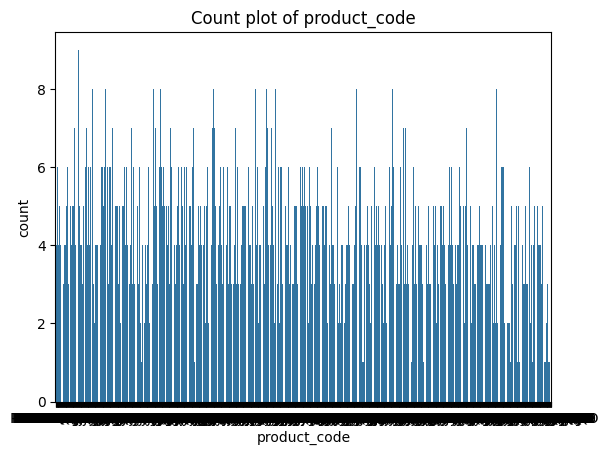

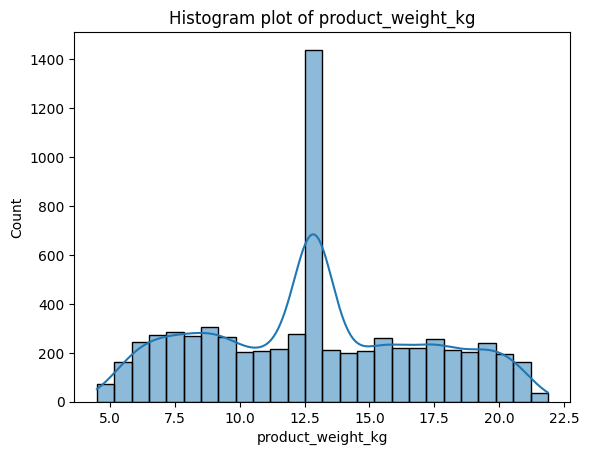

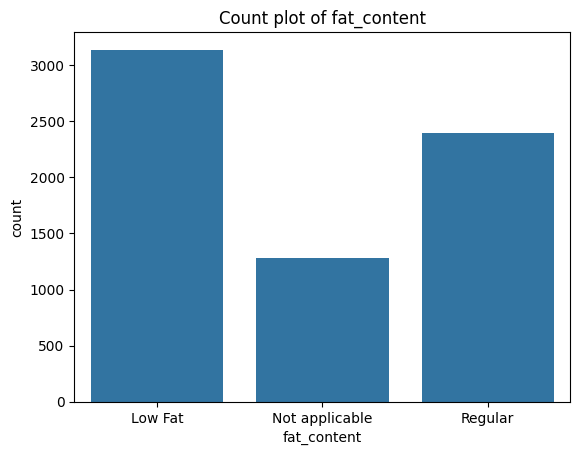

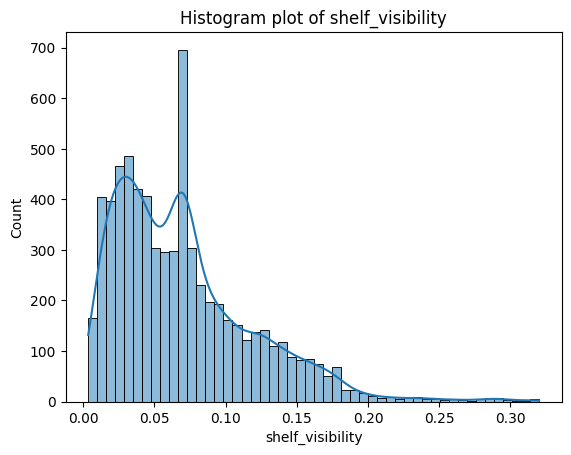

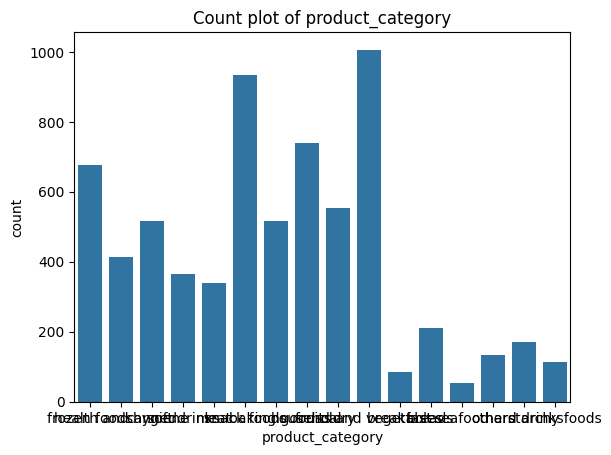

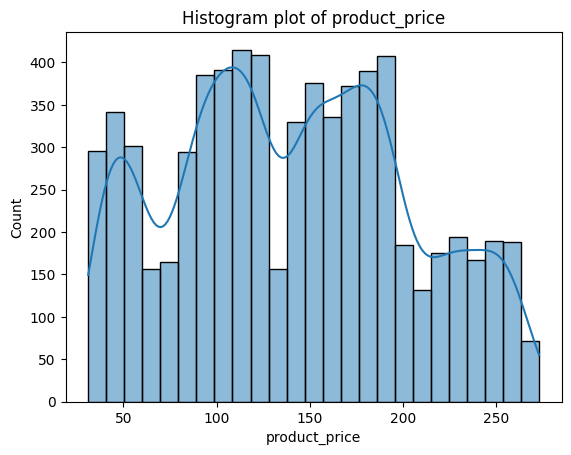

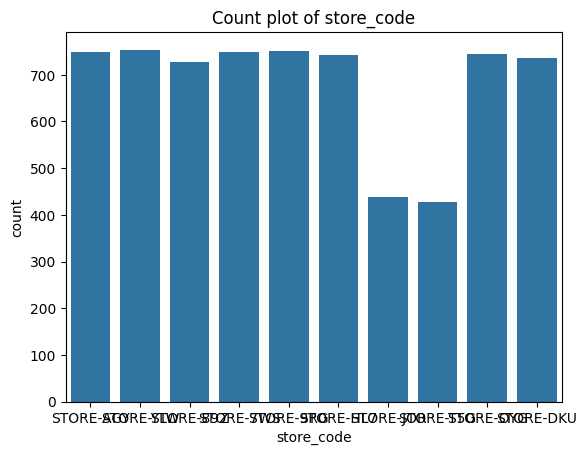

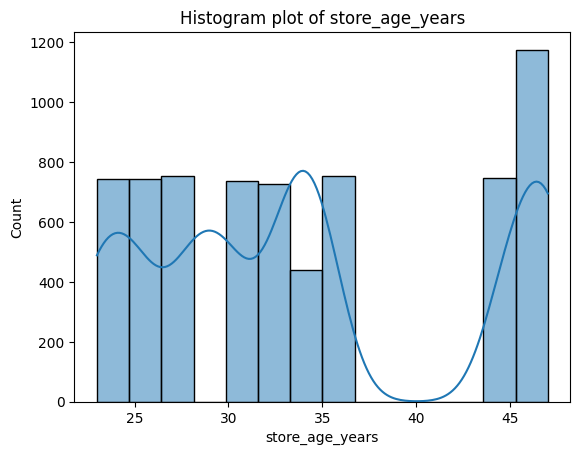

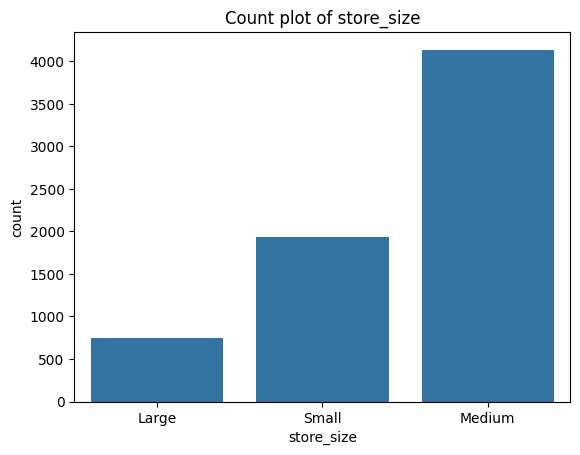

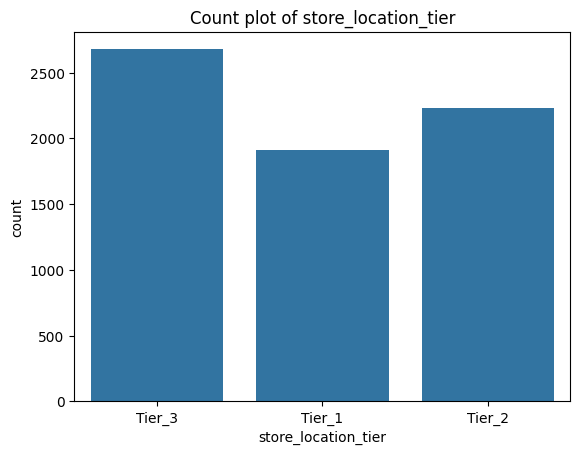

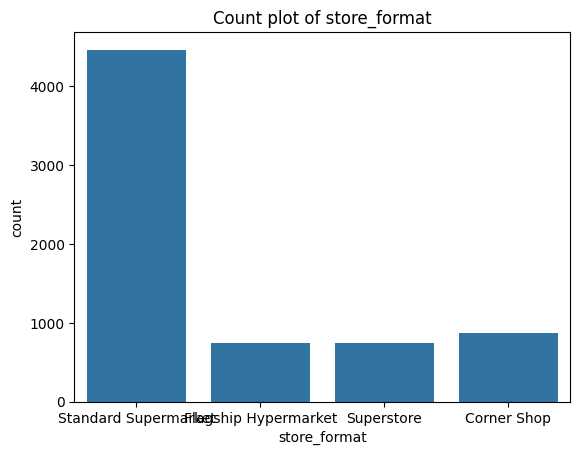

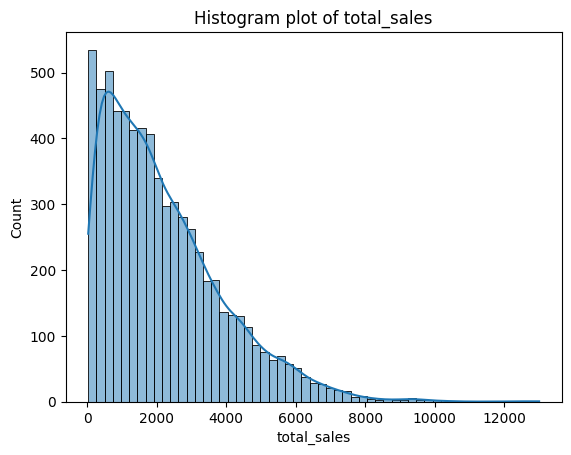

In [18]:
for col in df_train.columns:
  if df_train[col].dtype == 'object':
    sns.countplot(x=col, data=df_train)
    plt.title(f'Count plot of {col}')
    plt.show()

  elif df_train[col].dtype in ['int64', 'float64']:
    sns.histplot(data=df_train, x=col, kde=True)
    plt.title(f'Histogram plot of {col}')
    plt.show()

  else:
    print(f'Unsupported data type for {col}')

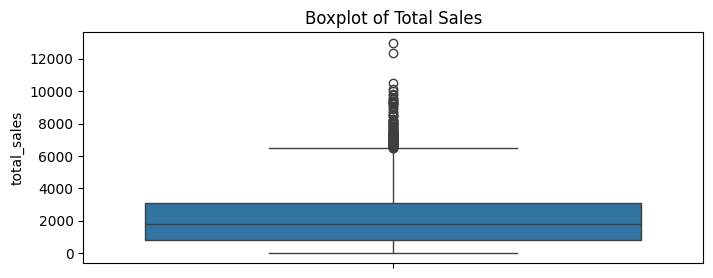

In [19]:
plt.figure(figsize=(8, 3))
sns.boxplot(y=df_train['total_sales'])
plt.title('Boxplot of Total Sales')
plt.show()


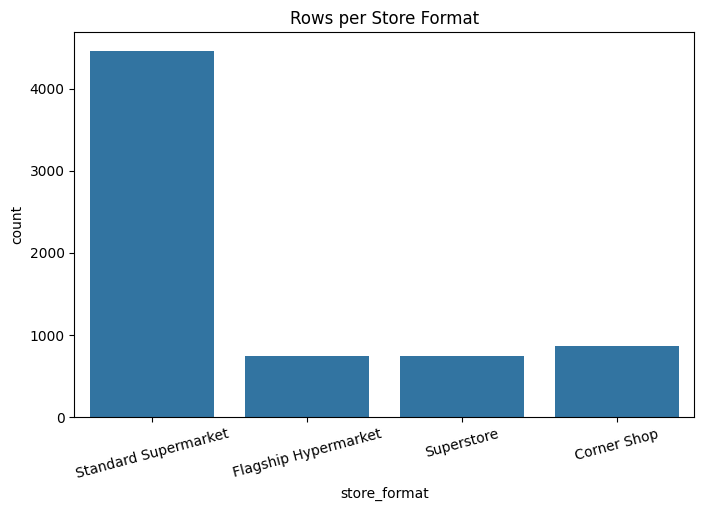

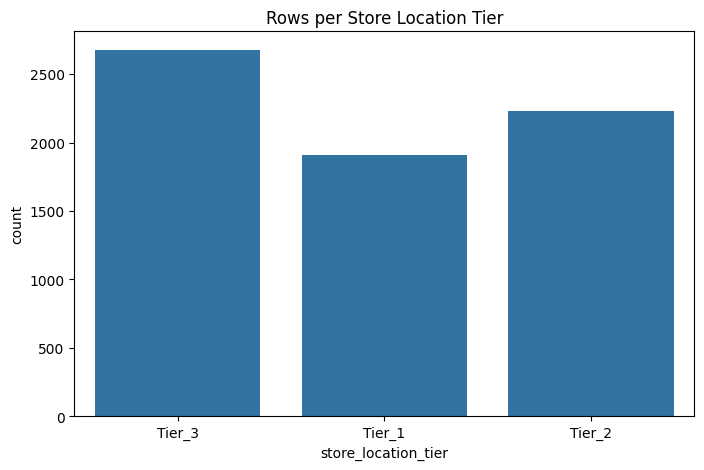

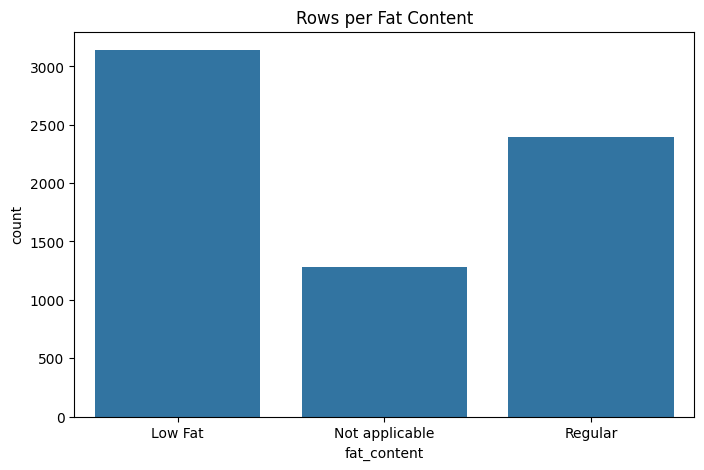

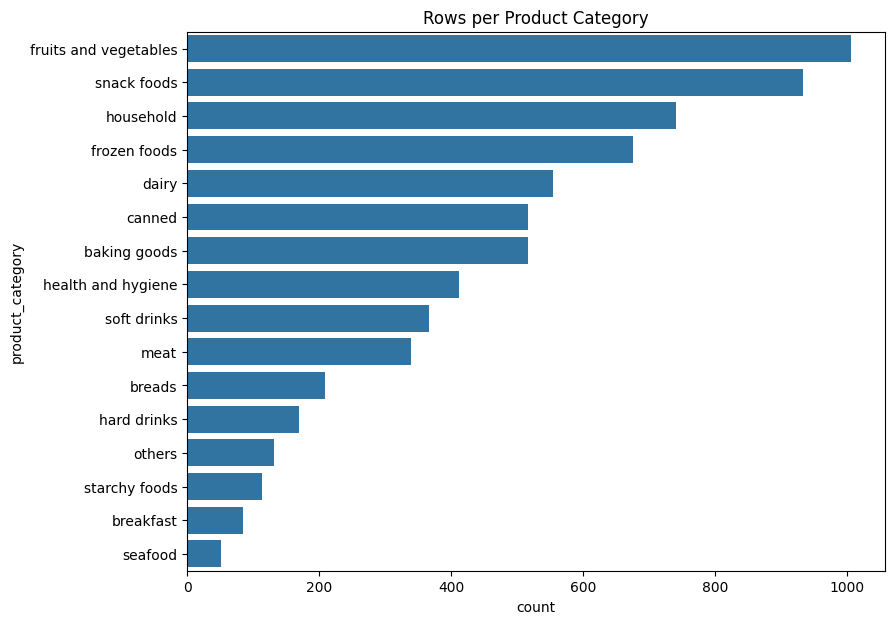

In [20]:
# Countplots: how many rows in each category?
plt.figure(figsize=(8, 5))
sns.countplot(data=df_train, x='store_format')
plt.title('Rows per Store Format')
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df_train, x='store_location_tier')
plt.title('Rows per Store Location Tier')
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df_train, x='fat_content')
plt.title('Rows per Fat Content')
plt.show()

plt.figure(figsize=(9, 7))
sns.countplot(data=df_train, y='product_category', order=df_train['product_category'].value_counts().index)
plt.title('Rows per Product Category')
plt.show()

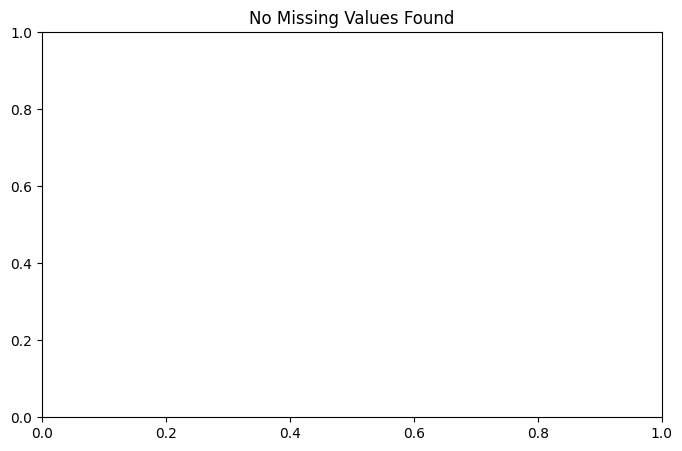

In [21]:
# Missing values: which columns have gaps? (% of rows)
plt.figure(figsize=(8, 5))
missing = df_train.isnull().mean().mul(100)
if not missing[missing > 0].empty:
    missing[missing > 0].plot(kind='bar')
    plt.title('Missing Values (%) per Column')
    plt.ylabel('% missing')
else:
    plt.title('No Missing Values Found')
plt.show()

#Bivariate Analysis

In [22]:
numeric_cols = ['product_weight_kg', 'shelf_visibility', 'product_price', 'store_age_years']
format_order = ['Corner Shop', 'Superstore', 'Standard Supermarket', 'Flagship Hypermarket']
tier_order = ['Tier_1', 'Tier_2', 'Tier_3']
fat_order = ['Low Fat', 'Regular', 'Not applicable']

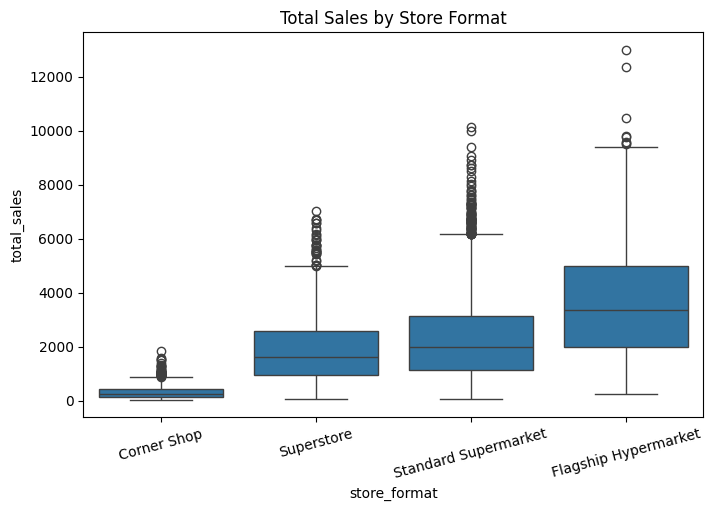

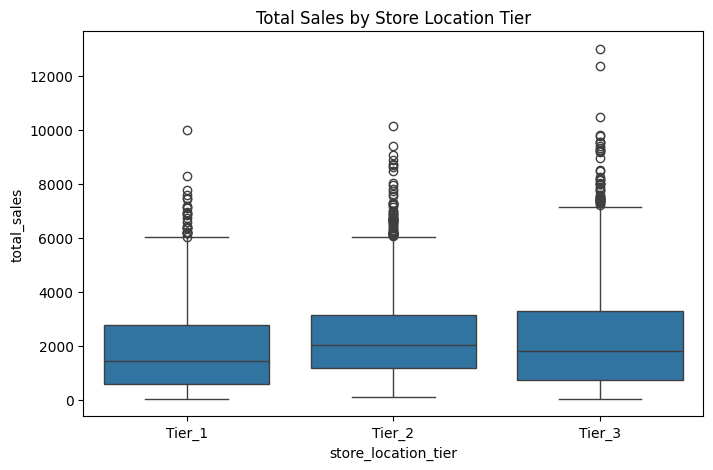

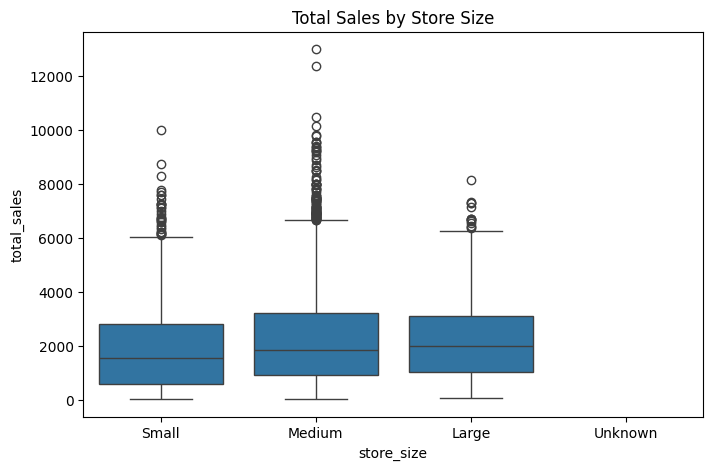

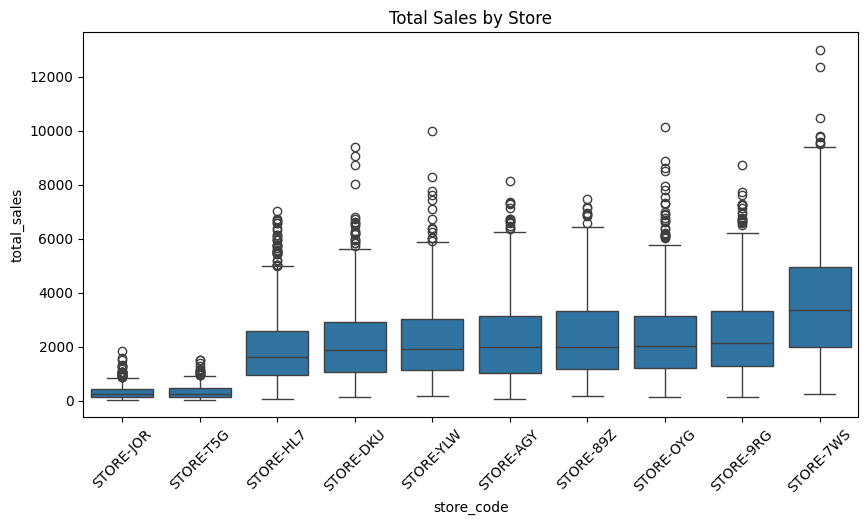

In [23]:
# Boxplot: sales spread across store formats
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_train, x='store_format', y='total_sales', order=format_order)
plt.title('Total Sales by Store Format')
plt.xticks(rotation=15)
plt.show()

# Boxplot: sales spread across store location tiers
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_train, x='store_location_tier', y='total_sales', order=tier_order)
plt.title('Total Sales by Store Location Tier')
plt.show()

# Boxplot: sales spread across store sizes
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_train, x='store_size', y='total_sales', order=['Small', 'Medium', 'Large', 'Unknown'])
plt.title('Total Sales by Store Size')
plt.show()

# Boxplot: sales spread across individual stores
plt.figure(figsize=(10, 5))
store_order = df_train.groupby('store_code')['total_sales'].median().sort_values().index   # sort stores by median sales
sns.boxplot(data=df_train, x='store_code', y='total_sales', order=store_order)
plt.title('Total Sales by Store')
plt.xticks(rotation=45)
plt.show()

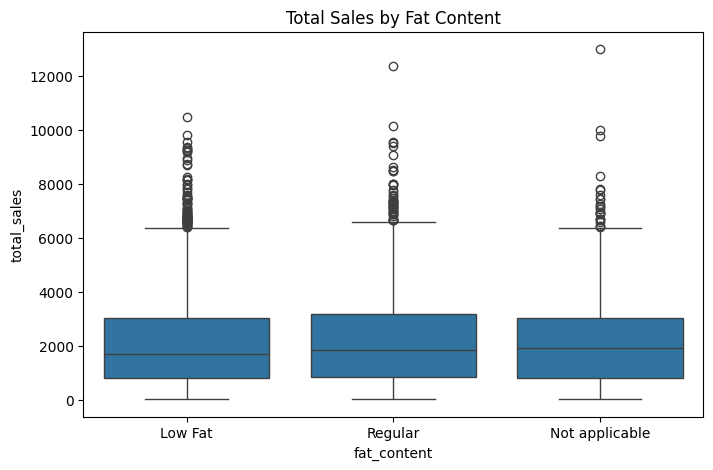

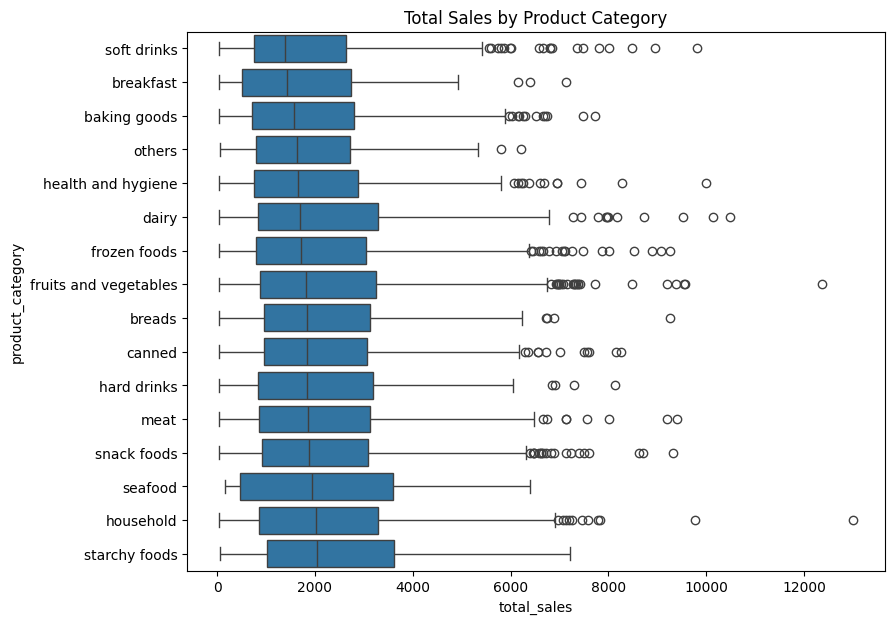

In [24]:
# Boxplot: sales spread across fat content
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_train, x='fat_content', y='total_sales', order=fat_order)
plt.title('Total Sales by Fat Content')
plt.show()

# Boxplot: sales spread across product categories
plt.figure(figsize=(9, 7))
category_order = df_train.groupby('product_category')['total_sales'].median().sort_values().index   # sort by median sales
sns.boxplot(data=df_train, y='product_category', x='total_sales', order=category_order)
plt.title('Total Sales by Product Category')
plt.show()

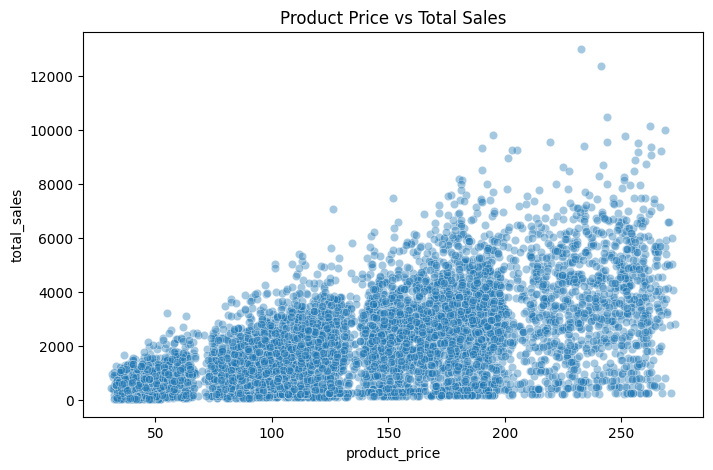

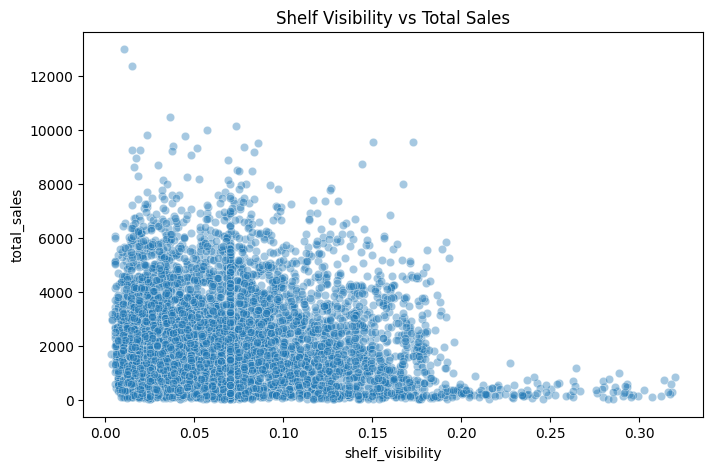

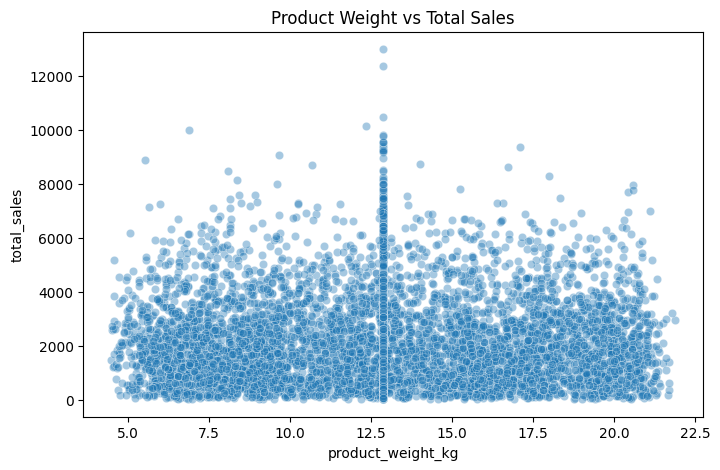

In [25]:
# Scatter plot: does higher price mean higher sales?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_train, x='product_price', y='total_sales', alpha=0.4)
plt.title('Product Price vs Total Sales')
plt.show()

# Scatter plot: does more shelf visibility mean more sales?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_train, x='shelf_visibility', y='total_sales', alpha=0.4)
plt.title('Shelf Visibility vs Total Sales')
plt.show()

# Scatter plot: does product weight matter?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_train, x='product_weight_kg', y='total_sales', alpha=0.4)
plt.title('Product Weight vs Total Sales')
plt.show()

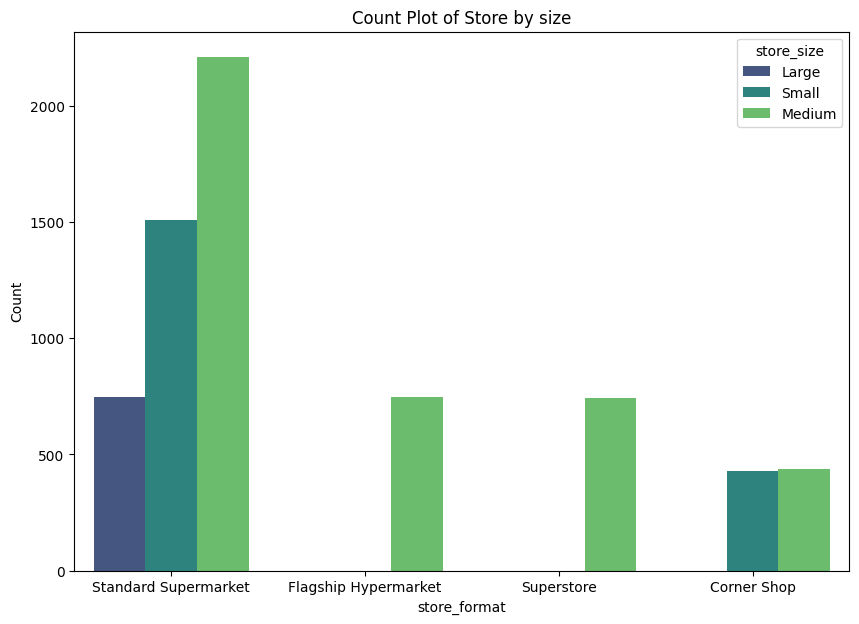

In [26]:
plt.figure(figsize=(10, 7))
sns.countplot(x='store_format', data=df_train,  hue='store_size', palette='viridis')
plt.title('Count Plot of Store by size')
plt.xlabel('store_format')
plt.ylabel('Count')
plt.show()

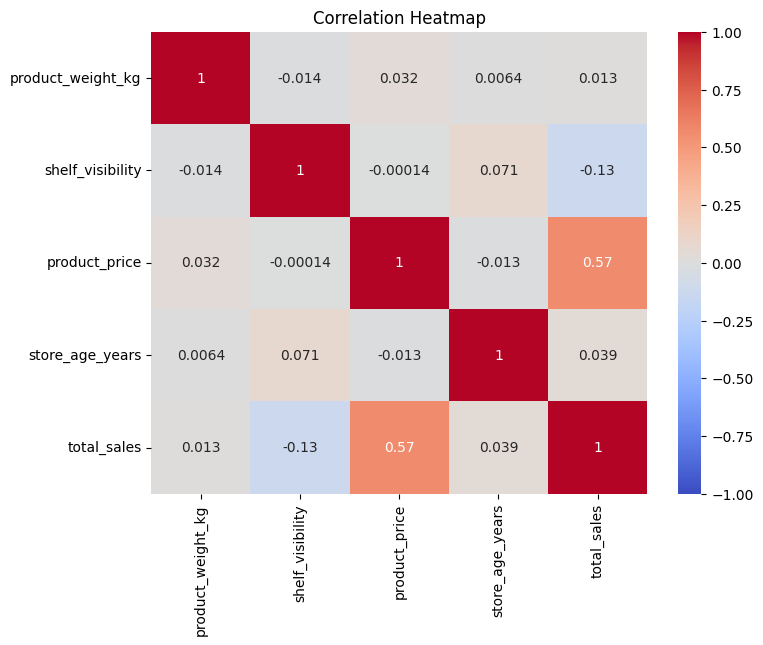

In [27]:
# Correlation heatmap: which numeric features move with sales?
plt.figure(figsize=(8, 6))
sns.heatmap(df_train[numeric_cols + ['total_sales']].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

#Multivariate Analysis

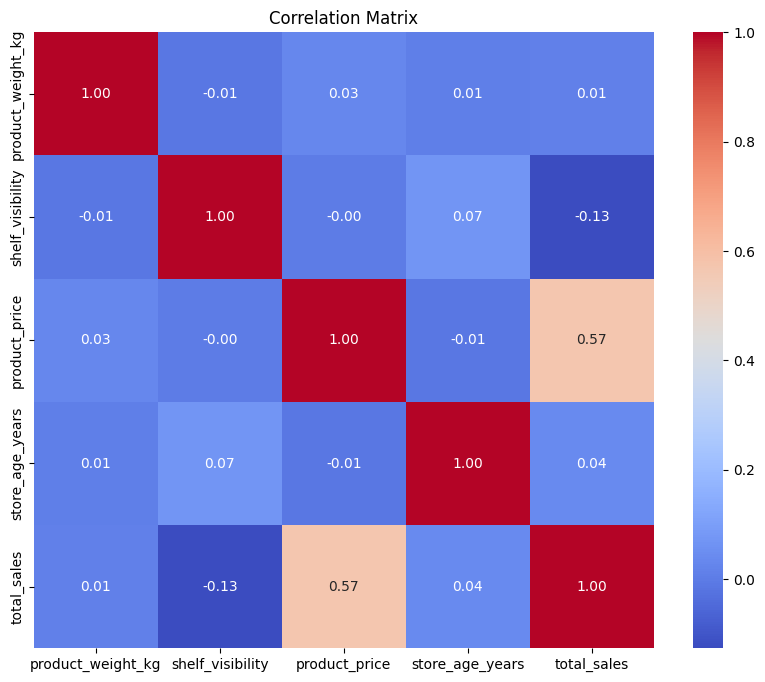

In [28]:
# Correlation matrix heatmap for numerical variables
plt.figure(figsize=(10, 8))
numeric_df = df_train.select_dtypes(include=[np.number]) # Filters only numbers
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

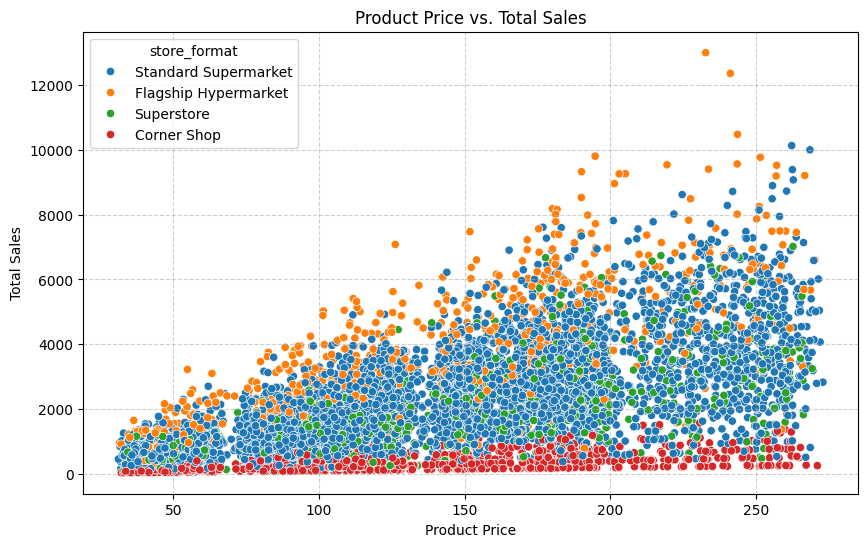

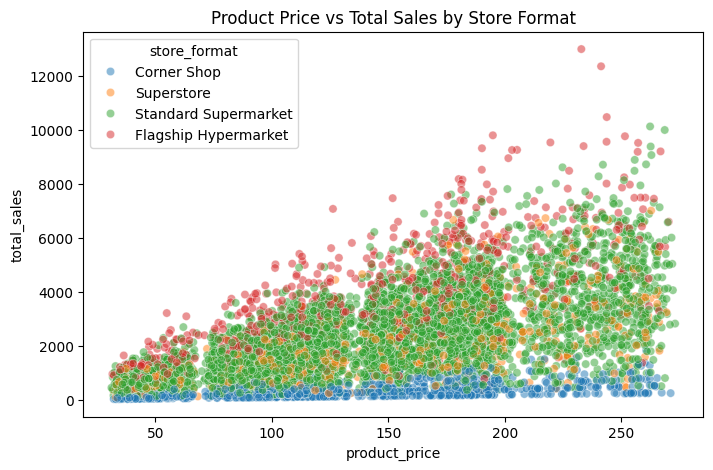

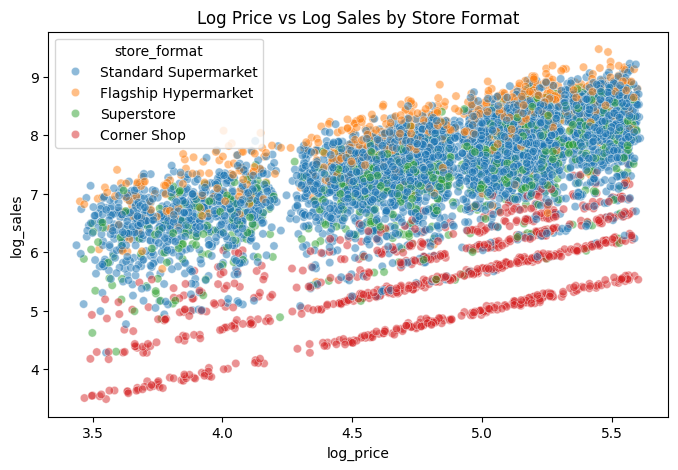

In [29]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_train, x='product_price', y='total_sales', hue='store_format')
plt.title('Product Price vs. Total Sales')
plt.xlabel('Product Price')
plt.ylabel('Total Sales')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# Scatter plot: price vs sales, coloured by store format
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_train, x='product_price', y='total_sales', hue='store_format', hue_order=format_order, alpha=0.5)
plt.title('Product Price vs Total Sales by Store Format')
plt.show()

# Create log-transformed columns for plotting on a log scale
df_train['log_price'] = np.log(df_train['product_price'])
df_train['log_sales'] = np.log(df_train['total_sales'])

# Same plot on a log scale: the cloud turns into clean, parallel bands (one per store format)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_train, x='log_price', y='log_sales', hue='store_format', alpha=0.5)
plt.title('Log Price vs Log Sales by Store Format')
plt.show()

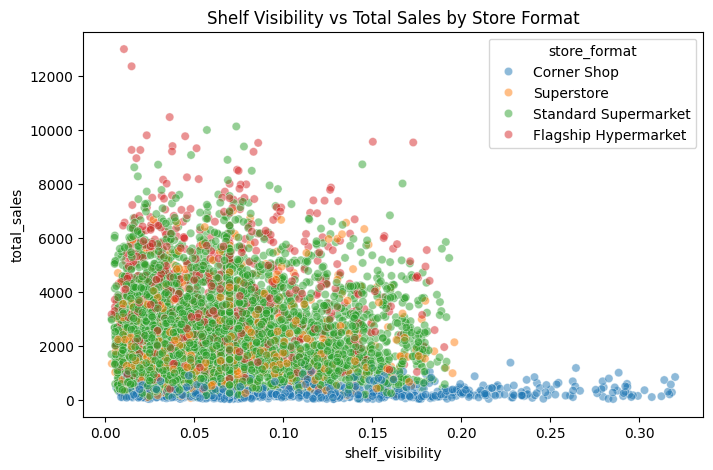

In [30]:
# Scatter plot: shelf visibility vs sales, coloured by store format
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_train, x='shelf_visibility', y='total_sales', hue='store_format', hue_order=format_order, alpha=0.5)
plt.title('Shelf Visibility vs Total Sales by Store Format')
plt.show()

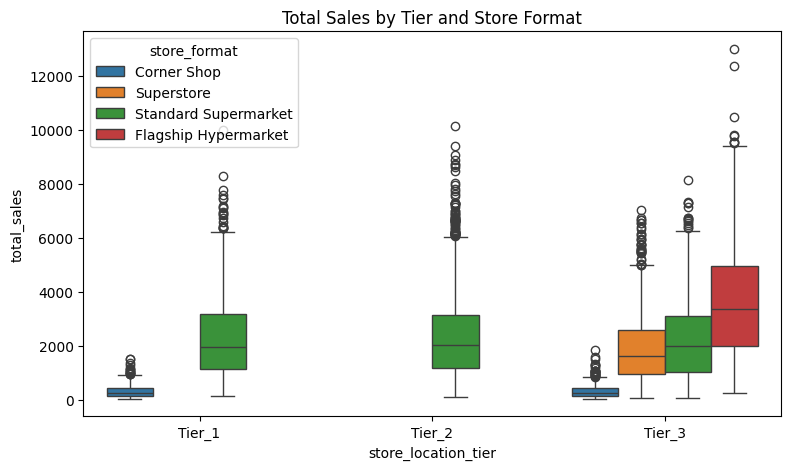

In [31]:
# Boxplot with a third variable: sales by tier, split by store format
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_train, x='store_location_tier', y='total_sales', order=tier_order, hue='store_format', hue_order=format_order)
plt.title('Total Sales by Tier and Store Format')
plt.show()

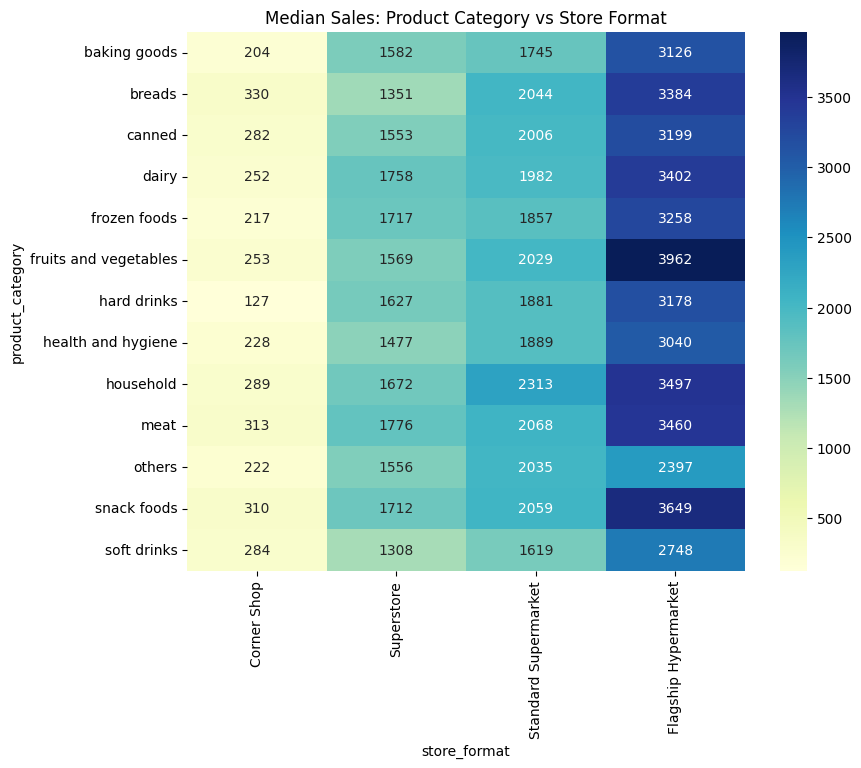

In [32]:
# Heatmap of median sales: product category x store format
plt.figure(figsize=(9, 7))
pivot = df_train.pivot_table(values='total_sales', index='product_category', columns='store_format', aggfunc='median')
pivot = pivot.drop(index=['seafood', 'breakfast', 'starchy foods'])   # rare categories: too few rows per cell
sns.heatmap(pivot[format_order], annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Median Sales: Product Category vs Store Format')
plt.show()

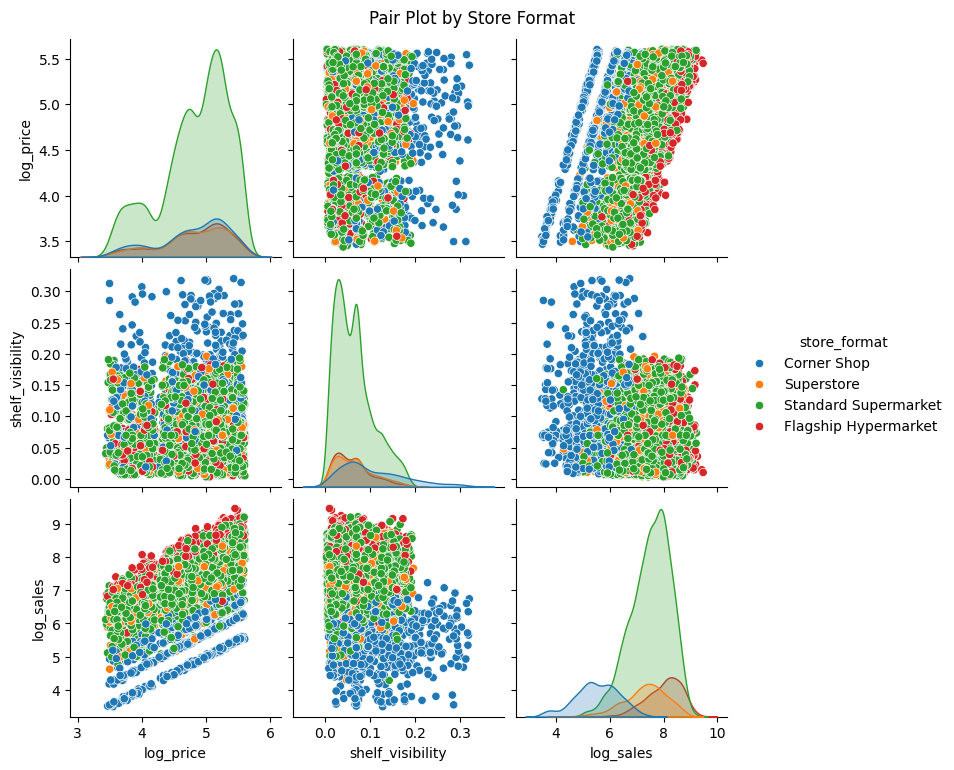

In [33]:
# Pair plot: every pair of key variables at once, coloured by store format
sns.pairplot(df_train, vars=['log_price', 'shelf_visibility', 'log_sales'], hue='store_format', hue_order=format_order)
plt.suptitle('Pair Plot by Store Format', y=1.02)
plt.show()

In [34]:
df_train.head(2)

,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales,log_price,log_sales
0,PRD-PRFP9S,14.252,Low Fat,0.0271,frozen foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98,4.399007,7.475895
1,PRD-PXXK71,7.698,Not applicable,0.0720,health and hygiene,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13,3.738859,5.835191


#Relevant *features*



In [35]:
df_train['units'] = df_train['total_sales'] / df_train['product_price']

# Average units by store format
format_avg_units = df_train.groupby('store_format')['units'].mean()

# Store effect relative to its store-format average
store_avg_units = df_train.groupby('store_code')['units'].mean()
store_format_map = df_train.groupby('store_code')['store_format'].first().map(format_avg_units)

store_offset = (store_avg_units - store_format_map).fillna(0)

# Product effect relative to its format average
df_train['fmt_avg_row'] = df_train['store_format'].map(format_avg_units)
product_stats = df_train.groupby('product_code').agg(
    n=('units', 'size'),
    product_avg=('units', 'mean'),
    format_avg=('fmt_avg_row', 'mean')
)
df_train = df_train.drop(columns=['fmt_avg_row'])
alpha = 30
product_offset = (
    product_stats['n'] *
    (product_stats['product_avg'] - product_stats['format_avg'])
    / (product_stats['n'] + alpha)
)

df_train = df_train.drop(columns=['units'])


In [36]:
model_meta = df_train[['store_format', 'store_code', 'product_code']].copy()

In [37]:
df_train.drop(['log_price', 'log_sales', 'product_code'], axis=1, inplace=True)

In [38]:
df_train['store_size'] = df_train['store_size'].map({'Small':0, 'Medium':1, 'Large':2})

df_train['store_location_tier'] = df_train['store_location_tier'].map({'Tier_1':0, 'Tier_2':1, 'Tier_3':2})

In [39]:
from sklearn.preprocessing import OneHotEncoder

categorical_features = ['store_code', 'store_format', 'fat_content', 'product_category']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

encoded_array = encoder.fit_transform(df_train[categorical_features])

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(categorical_features),
    index=df_train.index)

df_train = df_train.drop(columns=categorical_features)
df_train = pd.concat([df_train, encoded_df], axis=1)

In [40]:
df_train.head()

,product_weight_kg,shelf_visibility,product_price,store_age_years,store_size,store_location_tier,total_sales,store_code_STORE-7WS,store_code_STORE-89Z,store_code_STORE-9RG,...,product_category_fruits and vegetables,product_category_hard drinks,product_category_health and hygiene,product_category_household,product_category_meat,product_category_others,product_category_seafood,product_category_snack foods,product_category_soft drinks,product_category_starchy foods
0,14.252000,0.0271,81.37,45,2,2,1764.98,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,7.698000,0.0720,42.05,35,0,0,342.13,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,14.264000,0.0421,41.35,33,1,0,378.85,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,12.850876,0.0449,174.35,47,1,2,5595.72,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,10.338000,0.0120,203.06,28,0,1,2375.36,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [41]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 40 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   product_weight_kg                       6818 non-null   float64
 1   shelf_visibility                        6818 non-null   float64
 2   product_price                           6818 non-null   float64
 3   store_age_years                         6818 non-null   int64  
 4   store_size                              6818 non-null   int64  
 5   store_location_tier                     6818 non-null   int64  
 6   total_sales                             6818 non-null   float64
 7   store_code_STORE-7WS                    6818 non-null   float64
 8   store_code_STORE-89Z                    6818 non-null   float64
 9   store_code_STORE-9RG                    6818 non-null   float64
 10  store_code_STORE-AGY                    6818 non-null   floa

#Build and evaluate

In [42]:
!pip install catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.5 MB/s eta 0:00:00


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,  r2_score

In [44]:
y = df_train['total_sales'] / df_train['product_price']   # predict units, not sales directly
X = df_train.drop(['total_sales'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error: ", mse)
print('Mean Absolute Error:', mae)
print('R-Square:', r2)

Mean Squared Error:  47.08556570338457
Mean Absolute Error: 5.252054140825965
R-Square: 0.434405728422389


In [46]:
forest_model = RandomForestRegressor()

forest_model.fit(X_train, y_train)

y_pred = forest_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error: ", mse)
print('Mean Absolute Error:', mae)
print('R-Square:', r2)

Mean Squared Error:  51.81943513449773
Mean Absolute Error: 5.549032865617451
R-Square: 0.3775422418604869


In [47]:
boosting_model = HistGradientBoostingRegressor()

boosting_model.fit(X_train, y_train)

y_pred = boosting_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error: ", mse)
print('Mean Absolute Error:', mae)
print('R-Square:', r2)

Mean Squared Error:  50.62322720435776
Mean Absolute Error: 5.4656658003986465
R-Square: 0.391911153920818


In [48]:
xgb_model = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)

In [49]:
catboost_model = CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, random_state=42, verbose=False)

catboost_model.fit(X_train, y_train)

y_pred = catboost_model.predict(X_test)

In [50]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

kf = KFold(n_splits=5, shuffle=True, random_state=42)

price_all = df_train['product_price'].to_numpy()
sales_all = df_train['total_sales'].to_numpy()

oof_struct = np.zeros(len(X))
oof_cat = np.zeros(len(X))

alpha = 30

for train_idx, val_idx in kf.split(X):
    X_fold_train, X_fold_val = X.iloc[train_idx], X.iloc[val_idx]
    y_fold_train = y.iloc[train_idx]

    fold_meta = model_meta.iloc[train_idx].copy()
    fold_meta['units'] = y_fold_train.to_numpy()

    format_avg_fold = fold_meta.groupby('store_format')['units'].mean()
    fold_meta['format_avg'] = fold_meta['store_format'].map(format_avg_fold)

    # store-level offset, fold-safe (matches your cell 67 addition)
    store_avg_fold = fold_meta.groupby('store_code')['units'].mean()
    store_base_fold = fold_meta.groupby('store_code')['format_avg'].first()
    store_offset_fold = (store_avg_fold - store_base_fold).fillna(0)

    product_stats_fold = fold_meta.groupby('product_code').agg(
        n=('units', 'size'), product_avg=('units', 'mean'), format_avg=('format_avg', 'mean')
    )
    product_offset_fold = (
        product_stats_fold['n'] * (product_stats_fold['product_avg'] - product_stats_fold['format_avg'])
        / (product_stats_fold['n'] + alpha)
    )

    val_meta = model_meta.iloc[val_idx]
    struct_units = (
        val_meta['store_format'].map(format_avg_fold).fillna(y_fold_train.mean())
        + val_meta['store_code'].map(store_offset_fold).fillna(0)
        + val_meta['product_code'].map(product_offset_fold).fillna(0)
    ).clip(lower=0.3)

    catboost_fold = CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, random_state=42, verbose=False)
    catboost_fold.fit(X_fold_train, y_fold_train)

    oof_struct[val_idx] = struct_units.to_numpy()
    oof_cat[val_idx] = catboost_fold.predict(X_fold_val)

oof_blend = (0.9 * oof_struct + 0.1 * oof_cat).clip(min=0)

def sales_rmse(predicted_units):
    return mean_squared_error(sales_all, np.maximum(predicted_units, 0) * price_all) ** 0.5

print('Structure only:', round(sales_rmse(oof_struct), 2))
print('CatBoost only:  ', round(sales_rmse(oof_cat), 2))
print('Final blend:    ', round(sales_rmse(oof_blend), 2))

Structure only: 1070.95
CatBoost only:   1076.24
Final blend:     1070.89


In [51]:
from sklearn.model_selection import KFold, cross_val_score

# Initialize Linear Regression model
linear_model_cv = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = -cross_val_score(linear_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"Cross-validation RMSE scores: {cv_scores}")
print(f"Mean cross-validation RMSE: {cv_scores.mean():.4f}")
print(f"Standard deviation of cross-validation RMSE: {cv_scores.std():.4f}")

Cross-validation RMSE scores: [6.86189228 6.9366705  7.13175441 7.09893738 6.81119976]
Mean cross-validation RMSE: 6.9681
Standard deviation of cross-validation RMSE: 0.1271


In [52]:
# Initialize RandomForestRegressor model
forest_model_cv = RandomForestRegressor()

cv_scores_forest = -cross_val_score(forest_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"Random Forest Cross-validation RMSE scores: {cv_scores_forest}")
print(f"Random Forest Mean cross-validation RMSE: {cv_scores_forest.mean():.4f}")
print(f"Random Forest Standard deviation of cross-validation RMSE: {cv_scores_forest.std():.4f}")

Random Forest Cross-validation RMSE scores: [7.17863666 7.21261494 7.42867538 7.43965378 6.99770838]
Random Forest Mean cross-validation RMSE: 7.2515
Random Forest Standard deviation of cross-validation RMSE: 0.1661


In [53]:
# Initialize HistGradientBoostingRegressor model
boosting_model_cv = HistGradientBoostingRegressor()

cv_scores_boosting = -cross_val_score(boosting_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"Gradient Boosting Cross-validation RMSE scores: {cv_scores_boosting}")
print(f"Gradient Boosting Mean cross-validation RMSE: {cv_scores_boosting.mean():.4f}")
print(f"Gradient Boosting Standard deviation of cross-validation RMSE: {cv_scores_boosting.std():.4f}")

Gradient Boosting Cross-validation RMSE scores: [7.11500015 7.09108118 7.32754232 7.33350749 7.02133576]
Gradient Boosting Mean cross-validation RMSE: 7.1777
Gradient Boosting Standard deviation of cross-validation RMSE: 0.1285


In [54]:
# Initialize XGBoost model
xgb_model_cv = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)

cv_scores_xgb = -cross_val_score(xgb_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"XGBoost Cross-validation RMSE scores: {cv_scores_xgb}")
print(f"XGBoost Mean cross-validation RMSE: {cv_scores_xgb.mean():.4f}")
print(f"XGBoost Standard deviation of cross-validation RMSE: {cv_scores_xgb.std():.4f}")

XGBoost Cross-validation RMSE scores: [7.00436768 7.02428559 7.21656323 7.23790352 6.86459275]
XGBoost Mean cross-validation RMSE: 7.0695
XGBoost Standard deviation of cross-validation RMSE: 0.1402


In [55]:
# Initialize CatBoost model
catboost_model_cv = CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, random_state=42, verbose=False)

cv_scores_catboost = -cross_val_score(catboost_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"CatBoost Cross-validation RMSE scores: {cv_scores_catboost}")
print(f"CatBoost Mean cross-validation RMSE: {cv_scores_catboost.mean():.4f}")
print(f"CatBoost Standard deviation of cross-validation RMSE: {cv_scores_catboost.std():.4f}")

CatBoost Cross-validation RMSE scores: [6.90563133 6.94647342 7.14077892 7.10188051 6.8134458 ]
CatBoost Mean cross-validation RMSE: 6.9816
CatBoost Standard deviation of cross-validation RMSE: 0.1225


#Testing

In [56]:
df_test = pd.read_csv('/content/drive/MyDrive/Datasets/dsn-bootcamp-qualification-hackathon-2026-ml-track/test.csv')

In [57]:
df_test.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format
0,row_00009,PRD-2WLNC8,8.628,Low Fat,0.0167,household,190.72,STORE-HL7,23,Medium,Tier_3,Superstore
1,row_00015,PRD-LV9PLM,6.993,Low Fat,0.0579,Health and Hygiene,261.07,STORE-9RG,28,Small,Tier_2,Standard Supermarket
2,row_00019,PRD-ET6ZI7,NaN,Low Fat,0.1262,FRUITS AND VEGETABLES,112.50,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket
3,row_00020,PRD-6RX35U,14.034,Regular,0.0761,frozen foods,200.71,STORE-DKU,30,NaN,Tier_2,Standard Supermarket
4,row_00023,PRD-I4J38V,13.063,Low Fat,0.0650,Frozen Foods,150.59,STORE-89Z,33,Medium,Tier_1,Standard Supermarket


In [58]:
  if True:
    df_test_processed = df_test.copy()

    # Store IDs for submission before dropping
    test_ids = df_test_processed['id']

    df_test_processed['product_category'] = df_test_processed['product_category'].str.lower()

    df_test_processed.loc[df_test_processed['product_category'].isin(['household', 'health and hygiene', 'others']),
                          'fat_content'] = 'Not applicable'

    df_test_processed['shelf_visibility'] = df_test_processed['shelf_visibility'].replace(0, np.nan)

    df_test_processed['product_weight_kg'] = df_test_processed['product_weight_kg'].fillna(df_train['product_weight_kg'].mean())
    df_test_processed['shelf_visibility'] = df_test_processed['shelf_visibility'].fillna(df_train['shelf_visibility'].mean())
    df_test_processed['store_size'] = df_test_processed['store_size'].fillna(df_train['store_size'].mode()[0])

    df_test_processed = df_test_processed.drop(['id', 'product_code'], axis=1)

    df_test_processed['store_size'] = df_test_processed['store_size'].map({'Small':0, 'Medium':1, 'Large':2})
    df_test_processed['store_size'] = df_test_processed['store_size'].fillna(X['store_size'].mode()[0])

    df_test_processed['store_location_tier'] = df_test_processed['store_location_tier'].map({'Tier_1':0, 'Tier_2':1, 'Tier_3':2})
    df_test_processed['store_location_tier'] = df_test_processed['store_location_tier'].fillna(X['store_location_tier'].mode()[0])

    test_encoded_array = encoder.transform(df_test_processed[categorical_features])
    test_encoded_df = pd.DataFrame(
        test_encoded_array,
        columns=encoder.get_feature_names_out(categorical_features),
        index=df_test_processed.index
    )

    df_test_processed = df_test_processed.drop(columns=categorical_features)
    df_test_processed = pd.concat([df_test_processed, test_encoded_df], axis=1)

    df_test_processed = df_test_processed[X.columns]

    df_test_processed = df_test_processed.fillna(X.mean())

test_struct_units = (
    df_test['store_format'].map(format_avg_units)
    + df_test['store_code'].map(store_offset).fillna(0)
    + df_test['product_code'].map(product_offset).fillna(0)
).clip(lower=0.3)

xgb_model.fit(X, y)

catboost_model.fit(X, y)

test_catboost_units = catboost_model.predict(df_test_processed)

blend_units = (
    0.9 * test_struct_units.to_numpy()
    + 0.1 * test_catboost_units
).clip(min=0)


# Use the price supplied for each test row.

predicted_sales = blend_units * df_test['product_price'].to_numpy()

submission = pd.DataFrame({

    'id': test_ids,

    'total_sales': predicted_sales
})

submission.to_csv('submission.csv', index=False)
print('Saved predictions for', len(submission), 'rows to submission.csv')

Saved predictions for 1705 rows to submission.csv


In [59]:
print(submission['total_sales'].describe())

count    1705.000000
mean     2192.179200
std      1328.031715
min        70.644904
25%      1176.096528
50%      2064.170756
75%      3058.577247
max      6907.965646
Name: total_sales, dtype: float64


In [60]:
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
# Initialize RandomForestRegressor model
forest_model_cv = RandomForestRegressor()

cv_scores_forest = -cross_val_score(forest_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"Random Forest Cross-validation RMSE scores: {cv_scores_forest}")
print(f"Random Forest Mean cross-validation RMSE: {cv_scores_forest.mean():.4f}")
print(f"Random Forest Standard deviation of cross-validation RMSE: {cv_scores_forest.std():.4f}")

# Initialize HistGradientBoostingRegressor model
boosting_model_cv = HistGradientBoostingRegressor()

cv_scores_boosting = -cross_val_score(boosting_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"Gradient Boosting Cross-validation RMSE scores: {cv_scores_boosting}")
print(f"Gradient Boosting Mean cross-validation RMSE: {cv_scores_boosting.mean():.4f}")
print(f"Gradient Boosting Standard deviation of cross-validation RMSE: {cv_scores_boosting.std():.4f}")

Random Forest Cross-validation RMSE scores: [7.18788053 7.23305294 7.41598074 7.43252289 7.03268643]
Random Forest Mean cross-validation RMSE: 7.2604
Random Forest Standard deviation of cross-validation RMSE: 0.1495
Gradient Boosting Cross-validation RMSE scores: [7.11500015 7.09108118 7.32754232 7.33350749 7.02133576]
Gradient Boosting Mean cross-validation RMSE: 7.1777
Gradient Boosting Standard deviation of cross-validation RMSE: 0.1285


In [62]:
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Initialize XGBRegressor model
xgb_model_cv = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)

cv_scores_xgb = -cross_val_score(xgb_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"XGBoost Cross-validation RMSE scores: {cv_scores_xgb}")
print(f"XGBoost Mean cross-validation RMSE: {cv_scores_xgb.mean():.4f}")
print(f"XGBoost Standard deviation of cross-validation RMSE: {cv_scores_xgb.std():.4f}")

# Initialize CatBoostRegressor model
catboost_model_cv = CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, random_state=42, verbose=False)

cv_scores_catboost = -cross_val_score(catboost_model_cv, X, y, cv=kf, scoring='neg_root_mean_squared_error')

print(f"CatBoost Cross-validation RMSE scores: {cv_scores_catboost}")
print(f"CatBoost Mean cross-validation RMSE: {cv_scores_catboost.mean():.4f}")
print(f"CatBoost Standard deviation of cross-validation RMSE: {cv_scores_catboost.std():.4f}")

XGBoost Cross-validation RMSE scores: [7.00436768 7.02428559 7.21656323 7.23790352 6.86459275]
XGBoost Mean cross-validation RMSE: 7.0695
XGBoost Standard deviation of cross-validation RMSE: 0.1402
CatBoost Cross-validation RMSE scores: [6.90563133 6.94647342 7.14077892 7.10188051 6.8134458 ]
CatBoost Mean cross-validation RMSE: 6.9816
CatBoost Standard deviation of cross-validation RMSE: 0.1225
